# #204 Track A Gate B — market-anchored residual recovery

This executed notebook is a thin audit of the immutable `RETROSPECTIVE_IMPLEMENTATION_RECOVERY` package. It does not refit models, read labels, or choose parameters: the reusable runner performed the frozen fit/evaluation and this notebook verifies and renders its saved outputs.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import Image, Markdown, display

package = Path('results/bj204_gate_b_retrospective_implementation_recovery_v1')
assert package.is_dir(), package
manifest = json.loads((package / 'SHA256SUMS.json').read_text())
bad = [name for name, expected in manifest.items() if hashlib.sha256((package / name).read_bytes()).hexdigest() != expected]
assert not bad, bad
print(f'Package manifest PASS: {len(manifest)} payloads')

Package manifest PASS: 22 payloads


## Frozen contract and source binding

In [2]:
config = json.loads((package / 'model_config.json').read_text())
provenance = json.loads((package / 'provenance.json').read_text())
display(pd.DataFrame([{'version': config['version'], 'execution_status': config['execution_status'], 'composition': config['probability_composition'], 'gate_a_manifest': config['gate_a_manifest_sha256'], 'label_source_sha256': provenance['official_label_source_sha256']}]))
display(pd.DataFrame(config['models']).T)

,version,execution_status,composition,gate_a_manifest,label_source_sha256
0,bj204-market-anchored-model-gate-b-retrospecti...,RETROSPECTIVE_IMPLEMENTATION_RECOVERY,softmax(log(frozen_market_probability_3_1_0) +...,dfa14d42410d5513cbb07f832972e47fa1cf819a6f1eec...,e7256d96a34c2f41ede349c87b9cd1efc7a61b104657a6...


,learning_rate,max_iter,max_leaf_nodes,package,hidden_layer_sizes,representation,scope,torch_status,C,implementation
HIST_GRADIENT_RESIDUAL,0.05,60,8,sklearn,NaN,NaN,NaN,NaN,NaN,NaN
ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,NaN,50,NaN,sklearn,[32],permutation_invariant_issue_mean_std_max_min,issue-summary MLP control; not a learned-pooli...,not installed in frozen repository environment...,NaN,NaN
LOGISTIC_RESIDUAL,NaN,300,NaN,sklearn,NaN,NaN,NaN,NaN,0.5,NaN
SP_HEAD,NaN,60,NaN,sklearn,NaN,NaN,NaN,NaN,NaN,three HistGradientBoostingRegressor heads


## Development-only selection and locked-test scores

In [3]:
selection = pd.read_csv(package / 'model_selection.csv')
metrics = pd.read_csv(package / 'metrics.csv')
display(selection)
locked = metrics[(metrics['split'] == 'LOCKED_TEST') & metrics['view'].isin(['PURE_MARKET', 'MODEL_ONLY_COVERED', 'FALLBACK_MIXED'])]
display(locked.groupby(['model_id', 'view'], as_index=False)[['log_loss','brier','ece_equal_mass','top1','top2','sp_mae','model_used_rows','fallback_rows','ood_rows','mean_delta_logit_l1']].mean())

,model_id,mean_cv_log_loss,cv_rows,complexity_rank,selected_for_primary
0,MARKET_ONLY,1.150530,152394,0,True
1,HIST_GRADIENT_RESIDUAL,1.156824,152394,2,False
2,LOGISTIC_RESIDUAL,1.158564,152394,1,False
3,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,1.166829,152394,3,False


,model_id,view,log_loss,brier,ece_equal_mass,top1,top2,sp_mae,model_used_rows,fallback_rows,ood_rows,mean_delta_logit_l1
0,HIST_GRADIENT_RESIDUAL,FALLBACK_MIXED,1.150014,0.700833,0.153335,0.406503,0.734807,0.34515,16968.0,0.0,0.0,0.599276
1,HIST_GRADIENT_RESIDUAL,MODEL_ONLY_COVERED,1.150014,0.700833,0.153335,0.406503,0.734807,0.34515,16968.0,0.0,0.0,0.599276
2,HIST_GRADIENT_RESIDUAL,PURE_MARKET,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.599276
3,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,FALLBACK_MIXED,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,16968.0,16968.0,1.051034
4,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,MODEL_ONLY_COVERED,1.163824,0.704306,0.163208,0.414424,0.734767,0.34515,16968.0,0.0,16968.0,1.051034
5,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,PURE_MARKET,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,1.051034
6,LOGISTIC_RESIDUAL,FALLBACK_MIXED,1.152007,0.702865,0.157188,0.406404,0.731539,0.34515,16968.0,0.0,0.0,0.603206
7,LOGISTIC_RESIDUAL,MODEL_ONLY_COVERED,1.152007,0.702865,0.157188,0.406404,0.731539,0.34515,16968.0,0.0,0.0,0.603206
8,LOGISTIC_RESIDUAL,PURE_MARKET,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.603206
9,MARKET_ONLY,FALLBACK_MIXED,1.147860,0.696426,0.099572,0.399513,0.687697,0.34515,0.0,0.0,0.0,0.000000


## Exact matched-baseline differences, calibration and coverage

,model_id,lift_log_loss,lift_brier,lift_ece_equal_mass,lift_top1,lift_top2,lift_sp_mae
0,HIST_GRADIENT_RESIDUAL,0.002154,0.004406,0.053763,0.006990,0.047110,0.0
1,ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL,0.015964,0.007880,0.063636,0.014911,0.047070,0.0
2,LOGISTIC_RESIDUAL,0.004147,0.006439,0.057616,0.006891,0.043842,0.0


,bin,rows,mean_confidence,accuracy
0,1,1684,0.363741,0.352138
1,2,1684,0.387377,0.396081
2,3,1684,0.407937,0.417458
3,4,1683,0.428087,0.434343
4,5,1683,0.452865,0.448010
5,6,1683,0.482381,0.455140
6,7,1683,0.517296,0.397504
7,8,1683,0.558488,0.331551
8,9,1683,0.615982,0.363636
9,10,1683,0.727907,0.399287


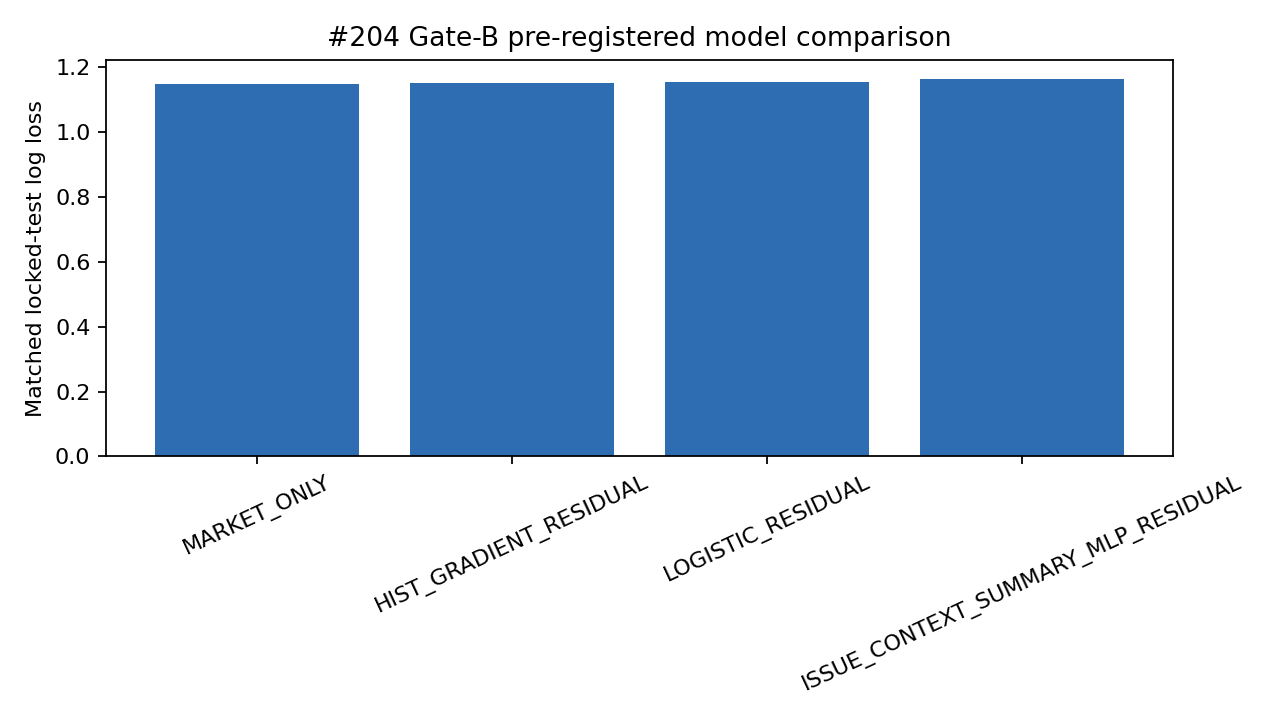

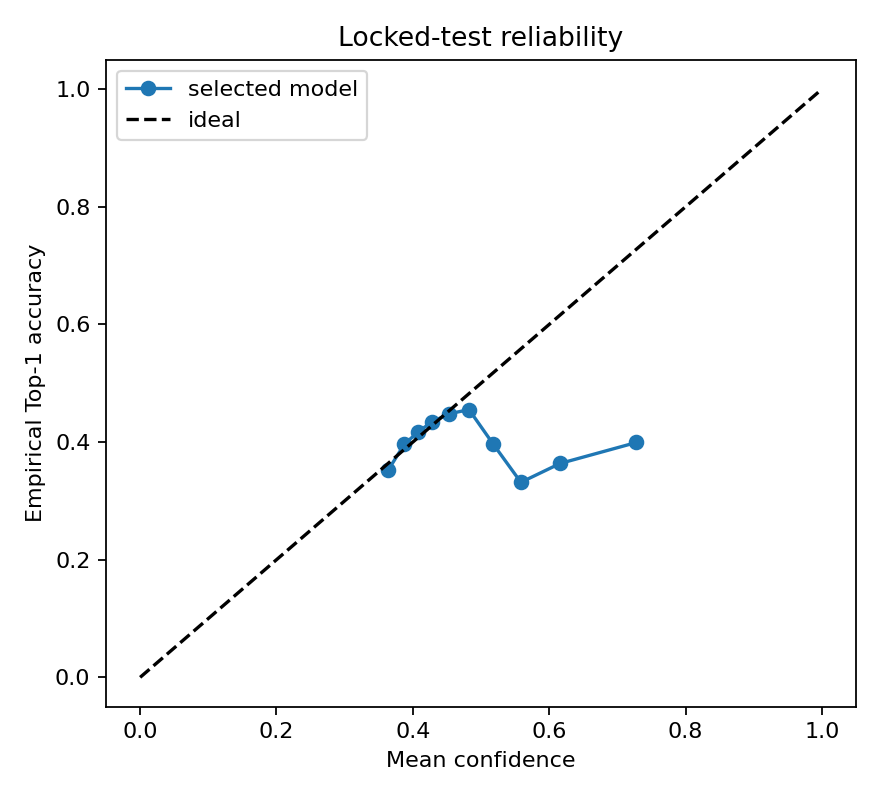

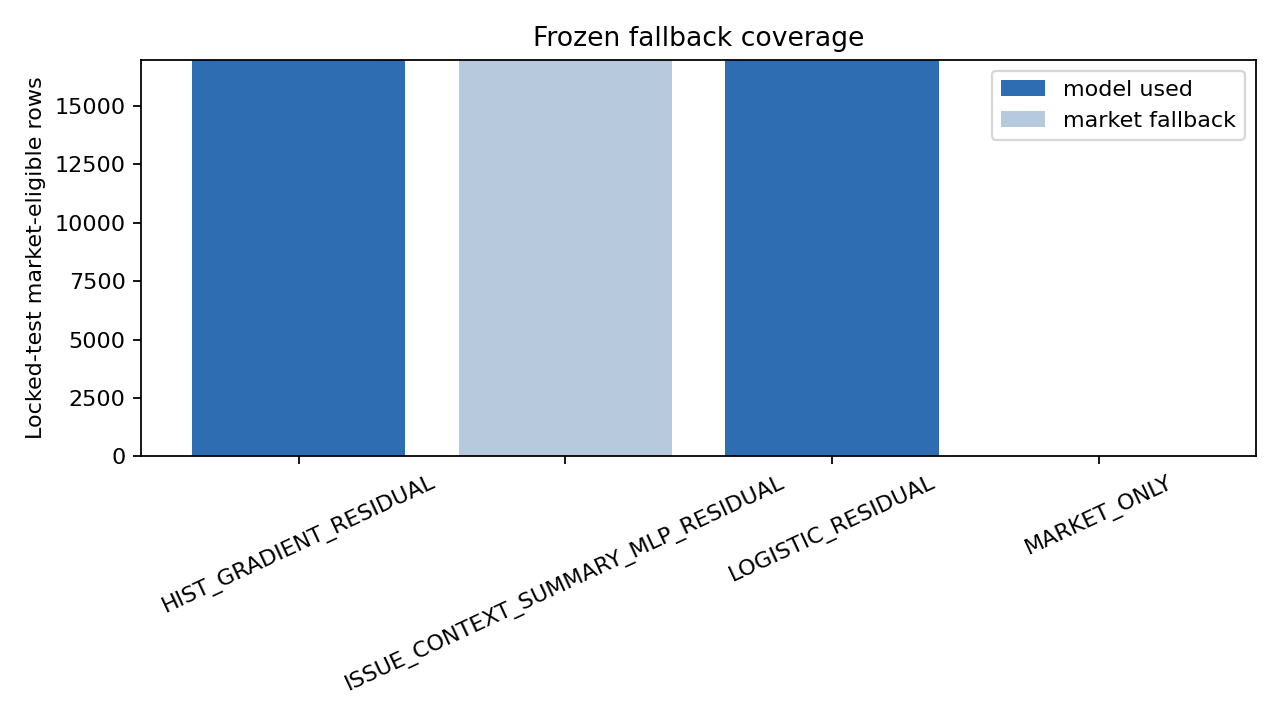

In [4]:
deltas = pd.read_csv(package / 'matched_baseline_deltas.csv')
display(deltas[deltas['split'] == 'LOCKED_TEST'].groupby('model_id', as_index=False)[['lift_log_loss','lift_brier','lift_ece_equal_mass','lift_top1','lift_top2','lift_sp_mae']].mean())
display(pd.read_csv(package / 'locked_test_calibration.csv'))
for filename in ('locked_test_log_loss.png', 'locked_test_calibration.png', 'locked_test_coverage.png'):
    display(Image(filename=str(package / filename)))

## Decision

In [5]:
display(Markdown((package / 'DECISION_REPORT.md').read_text()))

# #204 Gate B — bounded market-residual model decision

## Scope

This is a RETROSPECTIVE_IMPLEMENTATION_RECOVERY: pre-label residual corrections were frozen before the invalid v1 execution. It is proxy-grade research only and grants no betting, ROI, ticket, production, #205, or #210 authority.

## Frozen selection

The development-only expanding-CV rule selected `MARKET_ONLY`. No locked-test metric selected a model or hyperparameter.

## Locked 75-issue result

- Matched market-label rows: 16833.
- Model-only log loss: 1.147860; market: 1.147860; lift: 0.000000.
- Model-only Brier: 0.696426; market: 0.696426.
- Model-only ECE: 0.099572; market: 0.099572.
- Model-only Top1/Top2: 0.399513 / 0.687697; market: 0.399513 / 0.687697.

## Residual ablation versus the matched market baseline

Positive log-loss/Brier/ECE lift is worse; every pre-registered residual is worse on the locked test.
| Residual family | log-loss lift vs market | Brier lift | ECE lift | mean delta-logit L1 |
|---|---:|---:|---:|---:|
| HIST_GRADIENT_RESIDUAL | +0.002154 | +0.004406 | +0.053763 | 0.599276 |
| ISSUE_CONTEXT_SUMMARY_MLP_RESIDUAL | +0.015964 | +0.007880 | +0.063636 | 1.051034 |
| LOGISTIC_RESIDUAL | +0.004147 | +0.006439 | +0.057616 | 0.603206 |

## Safe fallback interpretation

The development-only rule selected the frozen MARKET_ONLY baseline. It is not a learned-model fallback event: it has zero model attempts, zero fallback substitutions, and zero OOD classifications.
Expected missing predicted-SP inputs are median-imputed with indicators and do not become synthetic OOD. This recovery cannot promote a probability or SP model; #210 remains the sole strict confirmation.

## Decision

`NO_PROMOTION_PENDING_PI_REVIEW`: retain the frozen market/NO_BET fallback and do not retune against the locked test.
